# UJIAN TENGAH SEMESTER (UTS) GASAL 2026/2027
## PROGRAM STUDI S1 SAINS DATA - FMIPA UNIVERSITAS NEGERI SURABAYA

* **Mata Kuliah**: Graf Sains Data (3 SKS)
* **Materi**: Python Driver untuk Neo4J, Graph Data Science, Vector Space Modelling (VSM), dan Sistem Rekomendasi (KNN & Analytics)
* **Nama Mahasiswa**: Muhammad Naza Firmansyah
* **NIM**: 24031554164
* **Sifat Ujian**: Individu
* **Dosen Pengampu**: TIM Dosen Graf Sains Data UNESA

---
### Ringkasan Pengerjaan:
Notebook ini memuat dokumentasi lengkap pengerjaan UTS Graf Sains Data:
1. **Tugas Pendahuluan**: Persiapan lingkungan (`uv`/`venv`), eksplorasi driver Neo4J Python API, jawaban *checkpoint*, dan skrip impor RetailRocket (`events.csv`).
2. **Soal 2.1 Wrangling dan EDA (45 Poin)**: Pemilihan 2 periode waktu unik berbasis NIM (16-17 Juli 2015 untuk Fold Training P1, 18-19 Juli 2015 untuk Fold Testing P2), filter timestamp & ekspor file `.csv`, query komposisi subgraph di Neo4j via Python API, pemodelan VSM simpul User & Item, analisis komparasi proyeksi, perhitungan similarity Cosine pada Python, penulisan kembali relasi `SIMILAR` ke Neo4j via Cypher SQL, dan visualisasi kondisi *sebelum vs sesudah*.
3. **Soal 2.2 Analytics (55 Poin)**: Pemilihan user secara acak dan *reproducible* (`seed` berbasis NIM), algoritma rekomendasi Item-based KNN ($k=5$), pemilihan 3 item yang diiklankan, serta evaluasi metrik `Hit@5` dan `NDCG@5` secara analitis dan matematis terhadap *ground truth* data uji P2.

---
# 1. Tugas Pendahuluan

## 1.1 Persiapan dan Perkenalan Lingkungan
Pengembangan dilakukan dalam lingkungan virtual environment terisolasi (`myvenv`) menggunakan Python 3.10 dan manajer paket modern `uv` untuk memastikan isolasi dependensi paket dari *local environment*.

Dependensi yang diinstal meliputi:
* `neo4j>=5.0` (kompatibel dengan driver Neo4j 6.4 API: `execute_query` dan `RoutingControl`)
* `pandas` & `numpy` (data wrangling & manipulasi matriks)
* `scipy` & `scikit-learn` (sparse matrix, VSM, dan perhitungan cosine similarity)
* `networkx` & `matplotlib` / `seaborn` (pemodelan graf, topologi, dan visualisasi)
* `tqdm` (progress bar untuk batch import)

In [1]:
# Verifikasi instalasi paket dan versi library
import os
import sys
import neo4j
import pandas as pd
import numpy as np
import scipy
import sklearn
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Python Version: {sys.version}")
print(f"Neo4j Driver Version: {neo4j.__version__}")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version: {np.__version__}")
print(f"NetworkX Version: {nx.__version__}")
print(f"Scikit-Learn Version: {sklearn.__version__}")

Python Version: 3.10.19 (main, Dec  9 2025, 18:58:23) [MSC v.1944 64 bit (AMD64)]
Neo4j Driver Version: 6.4.1
Pandas Version: 2.3.3
NumPy Version: 2.2.6
NetworkX Version: 3.4.2
Scikit-Learn Version: 1.7.2


## 1.2 Mempelajari Penggunaan Driver Neo4J
Berikut adalah implementasi tutorial driver Neo4J untuk menginisialisasi string koneksi, pembuatan objek node beserta relasinya, dan pembacaan data kembali.

In [2]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password")

def add_friend(driver, name, friend_name):
    """Membuat simpul Person dan relasi KNOWS"""
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    """Membaca dan menampilkan teman dari seorang Person"""
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    print(f"Teman dari {name}:")
    for record in records:
        print(f" - {record['friend.name']}")

# Jalankan pengujian
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Teman dari Arthur:
 - Guinevere
 - Lancelot
 - Merlin


### Pertanyaan Pendahuluan (Checkpoint)

#### 1. Apa nama database yang digunakan pada tutorial ini?
> **Jawaban:**  
> Nama database yang digunakan adalah **`neo4j`**. Hal ini terlihat secara eksplisit pada argumen parameter `database_="neo4j"` di pemanggilan fungsi `driver.execute_query(...)`. Pada instalasi Neo4j, `neo4j` merupakan nama database graf *default* tempat data disimpan dan dikueri.

#### 2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!
> **Jawaban:**  
> Pada instance Neo4j multi-database, akses ke database lain dapat dilakukan melalui beberapa mekanisme:
> 1. **Klausul Cypher `USE <database_name>`**: Dalam sesi kueri multi-database, klausul `USE` menentukan konteks database target, contohnya:
>    ```cypher
>    USE system
>    SHOW DATABASES;
>    ```
>    atau `USE myotherdb MATCH (n) RETURN count(n);`.
> 2. **Parameter Sesi pada Python Driver**: Mengatur parameter `database` saat membuka session:
>    ```python
>    session = driver.session(database="system")
>    # atau
>    session = driver.session(database="database_lain")
>    ```
> 3. **Perintah DDL Administratif Cypher (dijalankan di database `system`)**:
>    * `SHOW DATABASES;` : Menampilkan seluruh database dalam instance.
>    * `CREATE DATABASE nama_db;` : Membuat database baru.
>    * `STOP DATABASE nama_db;` & `START DATABASE nama_db;` : Mengatur status aktif database.
>    * `DROP DATABASE nama_db;` : Menghapus database.

#### 3. Apa jenis graf pertemanan yang telah dibuat di sini?
> **Jawaban:**  
> Graf yang dibuat adalah **Homogeneous Directed Graph** (Graf Berarah Homogen).  
> * **Homogen**: Semua simpul memiliki label yang seragam (`:Person`) dan semua relasi bertipe sama (`[:KNOWS]`).  
> * **Berarah (*Directed*)**: Hubungan bersifat satu arah dari simpul sumber ke target `(a)-[:KNOWS]->(friend)`.  
> * **Topologi**: Membentuk topologi **Ego-Network (Star Graph)** dengan simpul `Arthur` sebagai simpul pusat (*hub* / ego) dengan *in-degree* = 0 dan *out-degree* = 3 menuju `Guinevere`, `Lancelot`, dan `Merlin`.

In [3]:
# Pembersihan konten database tutorial (CYPHER Total Reset)
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
    print("Database tutorial berhasil di-reset bersih (0 nodes).")

Database tutorial berhasil di-reset bersih (0 nodes).


## 1.3 Melakukan Proses Impor Data dari RetailRocket ke Database Neo4J
Dataset yang digunakan berasal dari *Roman Zykov (Retailrocket e-commerce dataset)* yang berisi interaksi pengguna di platform belanja daring.

### Rincian Fitur Dataset:
* `timestamp`: Waktu interaksi dalam format Unix Epoch (milidetik).
* `visitorid`: ID unik pengguna / pengunjung situs (*User*).
* `event`: Jenis interaksi pengguna, terdiri dari tiga nilai:
  1. `view` (pengguna melihat halaman produk)
  2. `addtocart` (pengguna memasukkan produk ke keranjang belanja)
  3. `transaction` (pengguna melakukan pembelian/transaksi produk)
* `itemid`: ID unik produk (*Item*).
* `transactionid`: ID transaksi pembelian, hanya terisi jika `event == 'transaction'`, bernilai `NaN` jika lainnya.

Berikut adalah fungsi impor batch yang mengimplementasikan `UNWIND`, `MERGE`, dan `CALL` subquery sesuai spesifikasi soal.

In [4]:
def create_constraints(session):
    """Membuat constraint UNIQUE pada Visitor(visitorId) dan Item(itemId) agar MERGE berjalan cepat"""
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
    print("Unique constraints berhasil dipastikan.")

def import_batch(tx, batch):
    """Cypher query batch import sesuai template panduan soal"""
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

---
# 2. Soal UTS

## 2.1 Wrangling dan EDA (Maks. skor: 45)

### Soal 2.1.1: Penentuan 2 Periode Waktu sebagai Filter Data Interaksi
Ketentuan: *Kombinasi periode yg dipilih per individu tidak boleh sama dalam 1 kelas.*

**Identitas Mahasiswa:**
* Nama: **Muhammad Naza Firmansyah**
* NIM: **24031554164** (3 digit terakhir: `164`)

**Penentuan Periode Waktu Sesuai Konvensi Kelas:**
Mengikuti metode holdout time-series split standar di kelas yang membagi keseluruhan rentang dataset RetailRocket (3 Mei 2015 hingga 18 September 2015), titik potong (*cut-off date*) ditentukan secara unik berdasarkan digit belakang NIM `164` (tanggal **16 Juli 2015**):
* **Fold Training (P1)**: **3 Mei 2015 s.d. 16 Juli 2015**
  * UNIX Timestamp Mulai: `1430622004384` (3 Mei 2015, 03:00:04 UTC)
  * UNIX Timestamp Selesai: `1437091183647` (16 Juli 2015, 23:59:43 UTC)
* **Fold Testing (P2)**: **17 Juli 2015 s.d. 18 September 2015**
  * UNIX Timestamp Mulai: `1437091199857` (17 Juli 2015, 00:00:00 UTC)
  * UNIX Timestamp Selesai: `1442545187788` (18 September 2015, 02:59:47 UTC)

**Keunggulan dan Rasionalisasi Pemilihan Periode Ini:**
1. **Unik dan Personal**: Titik potong tanggal 16 Juli diambil dari NIM `164`. Posisi tanggal 16 Juli ini sangat ideal dan unik di antara rekan sekelas (misal: Umi di 14 Juli dan Nadine di 21 Juli).
2. **Karakteristik Data Lengkap**: Membagi seluruh interaksi historis platform e-commerce (total >2,75 juta baris interaksi) menjadi masa pelatihan historis dan masa pengujian masa depan.
3. **Penyusunan Subgraph Representatif (Soal 2.1.3)**: Sesuai instruksi soal No. 3 (*"Lakukan query untuk mendapatkan komposisi dari **subgraph yang dibuat**..."*), dari partisi waktu P1 dan P2 yang masif ini, diekstraksi *subgraph interaksi aktif* di sekitar titik potong 16 Juli (16-17 Juli untuk pelatihan P1 dan 18-19 Juli untuk pengujian P2) dan disimpan ke `events_filtered.csv`. Hal ini menjaga efisiensi komputasi VSM, mencegah Out-of-Memory (OOM) pada RAM laptop saat perkalian matriks graf, serta menghasilkan visualisasi NetworkX yang rapi dan informatif.

### Soal 2.1.2: Terapkan Proses Filter pada Timestamp & Simpan File .csv
Partisi makro holdout dan subgraph interaksi difilter berdasarkan atribut `timestamp` (milidetik Unix Epoch) dan disimpan ke dalam file `events_filtered.csv`.

In [5]:
# Membaca dataset mentah RetailRocket
raw_csv_path = "data/events.csv"
print(f"Membaca {raw_csv_path}...")
df_raw = pd.read_csv(raw_csv_path)

# 1. Analisis Partisi Waktu Penuh Sesuai Konvensi Kelas
cut_off_timestamp = 1437091183647 # 16 Juli 2015 23:59:43 UTC

full_p1 = df_raw[df_raw['timestamp'] <= cut_off_timestamp]
full_p2 = df_raw[df_raw['timestamp'] > cut_off_timestamp]
common_users_full = set(full_p1['visitorid']).intersection(set(full_p2['visitorid']))

print("="*65)
print("PARTISI WAKTU PENUH HOLDOUT (3 MEI - 16 JULI vs 17 JULI - 18 SEPT)")
print("="*65)
print(f"P1 Training (Full) : {len(full_p1):,} baris | {full_p1['visitorid'].nunique():,} user | {full_p1['itemid'].nunique():,} item")
print(f"   UNIX Timestamp  : {full_p1['timestamp'].min()} s.d. {full_p1['timestamp'].max()}")
print(f"P2 Testing (Full)  : {len(full_p2):,} baris | {full_p2['visitorid'].nunique():,} user | {full_p2['itemid'].nunique():,} item")
print(f"   UNIX Timestamp  : {full_p2['timestamp'].min()} s.d. {full_p2['timestamp'].max()}")
print(f"Active Common Users: {len(common_users_full):,} pengguna aktif di kedua periode")
print("="*65)

# 2. Ekstraksi Subgraph Representatif untuk Analisis Graf di Neo4j & NetworkX
# Konversi epoch ke pandas datetime
df_raw['datetime'] = pd.to_datetime(df_raw['timestamp'], unit='ms')

p1_sub_start = '2015-07-16 00:00:00'
p1_sub_end   = '2015-07-17 23:59:59'
p2_sub_start = '2015-07-18 00:00:00'
p2_sub_end   = '2015-07-19 23:59:59'

mask_p1 = (df_raw['datetime'] >= p1_sub_start) & (df_raw['datetime'] <= p1_sub_end)
mask_p2 = (df_raw['datetime'] >= p2_sub_start) & (df_raw['datetime'] <= p2_sub_end)

df_p1 = df_raw[mask_p1].copy()
df_p1['fold'] = 'P1_train'

df_p2 = df_raw[mask_p2].copy()
df_p2['fold'] = 'P2_test'

df_filtered = pd.concat([df_p1, df_p2], ignore_index=True)
filtered_csv_path = "data/events_filtered.csv"
df_filtered.to_csv(filtered_csv_path, index=False)

print()
print("SUBGRAPH INTERAKSI REPRESENTATIF (DISIMPAN KE CSV UNTUK NEO4J & NETWORKX):")
print(f"Data Subgraph P1 : {len(df_p1):,} baris | {df_p1['visitorid'].nunique():,} user | {df_p1['itemid'].nunique():,} item")
print(f"Data Subgraph P2 : {len(df_p2):,} baris | {df_p2['visitorid'].nunique():,} user | {df_p2['itemid'].nunique():,} item")
print(f"File Berhasil Disimpan ke: {filtered_csv_path} ({os.path.getsize(filtered_csv_path)/1024/1024:.2f} MB)")

Membaca data/events.csv...


PARTISI WAKTU PENUH HOLDOUT (3 MEI - 16 JULI vs 17 JULI - 18 SEPT)


P1 Training (Full) : 1,556,454 baris | 789,013 user | 183,993 item
   UNIX Timestamp  : 1430622004384 s.d. 1437091183647


P2 Testing (Full)  : 1,199,647 baris | 652,040 user | 165,647 item
   UNIX Timestamp  : 1437091199857 s.d. 1442545187788
Active Common Users: 33,473 pengguna aktif di kedua periode



SUBGRAPH INTERAKSI REPRESENTATIF (DISIMPAN KE CSV UNTUK NEO4J & NETWORKX):
Data Subgraph P1 : 41,818 baris | 25,321 user | 22,788 item
Data Subgraph P2 : 33,293 baris | 20,204 user | 18,268 item
File Berhasil Disimpan ke: data/events_filtered.csv (4.85 MB)


### Soal 2.1.3: Query Komposisi Subgraph di Neo4j via Python API
Kita mengimpor data interaksi pelatihan (P1) ke dalam database Neo4j, lalu mengeksekusi kueri agregasi untuk mengetahui komposisi simpul dan relasi yang terbentuk.

In [6]:
# Membaca data P1 dari filtered CSV dan membersihkan nilai null pada transactionid
p1_clean = df_p1.copy()
p1_clean['transactionid'] = p1_clean['transactionid'].fillna('').astype(str)

batch_size = 5000
total_rows = len(p1_clean)

print(f"Memulai impor {total_rows:,} baris P1 ke Neo4j...")
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        # Reset graf lama
        session.run("MATCH (n) DETACH DELETE n")
        create_constraints(session)
        
        # Batching insert
        for start_idx in range(0, total_rows, batch_size):
            end_idx = min(start_idx + batch_size, total_rows)
            chunk = p1_clean.iloc[start_idx:end_idx].to_dict(orient="records")
            session.execute_write(import_batch, chunk)
            print(f" > Terimpor: {end_idx:,} / {total_rows:,} baris")
            
print("Impor selesai dengan sukses!")

Memulai impor 41,818 baris P1 ke Neo4j...


Unique constraints berhasil dipastikan.


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row, v, i, row, v, i, row) { ... }', position=<SummaryInputPosition line=6, column=5, offset=138>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 138, 'line': 6, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        UNION ALL\n       

 > Terimpor: 5,000 / 41,818 baris


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row, v, i, row, v, i, row) { ... }', position=<SummaryInputPosition line=6, column=5, offset=138>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 138, 'line': 6, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        UNION ALL\n       

...

 > Terimpor: 35,000 / 41,818 baris


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row, v, i, row, v, i, row) { ... }', position=<SummaryInputPosition line=6, column=5, offset=138>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 138, 'line': 6, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        UNION ALL\n       

 > Terimpor: 40,000 / 41,818 baris


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row, v, i, row, v, i, row) { ... }', position=<SummaryInputPosition line=6, column=5, offset=138>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 138, 'line': 6, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)\n        UNION ALL\n       

 > Terimpor: 41,818 / 41,818 baris
Impor selesai dengan sukses!


In [7]:
# Query komposisi subgraph menggunakan Neo4j Python API
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    # 1. Hitung jumlah simpul Visitor
    res_visitor, _, _ = driver.execute_query(
        "MATCH (v:Visitor) RETURN count(v) AS count",
        database_="neo4j", routing_=RoutingControl.READ
    )
    total_visitors = res_visitor[0]["count"]
    
    # 2. Hitung jumlah simpul Item
    res_item, _, _ = driver.execute_query(
        "MATCH (i:Item) RETURN count(i) AS count",
        database_="neo4j", routing_=RoutingControl.READ
    )
    total_items = res_item[0]["count"]
    
    # 3. Hitung rincian tipe relasi
    res_rels, _, _ = driver.execute_query(
        """
        MATCH ()-[r]->() 
        RETURN type(r) AS rel_type, count(r) AS rel_count 
        ORDER BY rel_count DESC
        """,
        database_="neo4j", routing_=RoutingControl.READ
    )
    
print("="*45)
print("KOMPOSISI SUBGRAPH YANG DIBANGUN DI NEO4J")
print("="*45)
print(f"1. Simpul :Visitor : {total_visitors:,} nodes")
print(f"2. Simpul :Item    : {total_items:,} nodes")
print(f"   Total Nodes     : {total_visitors + total_items:,} nodes")
print("-" * 45)
print("3. Rincian Relasi Edges:")
total_edges = 0
for r in res_rels:
    total_edges += r["rel_count"]
    print(f"   - [:{r['rel_type']}] : {r['rel_count']:,} relasi")
print(f"   Total Relasi    : {total_edges:,} edges")
print("="*45)

KOMPOSISI SUBGRAPH YANG DIBANGUN DI NEO4J
1. Simpul :Visitor : 25,321 nodes
2. Simpul :Item    : 22,788 nodes
   Total Nodes     : 48,109 nodes
---------------------------------------------
3. Rincian Relasi Edges:
   - [:VIEWED] : 40,376 relasi
   - [:ADDED_TO_CART] : 1,064 relasi
   - [:BOUGHT] : 378 relasi
   Total Relasi    : 41,818 edges


#### Penjelasan Sintaks CYPHER SQL yang Digunakan:
1. **Pemeriksaan Simpul Visitor**:
   ```cypher
   MATCH (v:Visitor) RETURN count(v) AS count
   ```
   *Keterangan:* Menggunakan pola `MATCH (v:Visitor)` untuk mencari semua simpul yang memiliki label `Visitor` dan menghitung jumlah totalnya menggunakan fungsi agregasi `count(v)`.
2. **Pemeriksaan Simpul Item**:
   ```cypher
   MATCH (i:Item) RETURN count(i) AS count
   ```
   *Keterangan:* Pola yang sama diterapkan pada label `Item`. Berkat adanya index/constraint unik pada `itemId`, query berjalan sangat cepat (*O(1)* lewat store statistics).
3. **Pemeriksaan Komposisi Relasi**:
   ```cypher
   MATCH ()-[r]->() 
   RETURN type(r) AS rel_type, count(r) AS rel_count 
   ORDER BY rel_count DESC
   ```
   *Keterangan:* Pola tanpa label simpul `()-[r]->()` mencocokkan setiap relasi berarah. Fungsi bawaan `type(r)` mengekstrak nama tipe relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`), kemudian dikelompokkan dan dihitung frekuensinya.

### Soal 2.1.4: Vector Space Modelling (VSM) terhadap Simpul User
Pada Vector Space Modelling untuk simpul User:
* Setiap baris mewakili **vektor profil User (Visitor)** $\mathbf{u}_i$.
* Setiap kolom mewakili dimensi produk (**Item**) $j$.
* Nilai elemen matriks $M_{i, j}$ merepresentasikan bobot interaksi user $i$ terhadap item $j$. Di sini diterapkan skema pembobotan implisit standar e-commerce:
  * `view` = 1
  * `addtocart` = 2
  * `transaction` = 3

In [8]:
from scipy.sparse import csr_matrix

# Membangun User-Item Matrix
event_weights = {'view': 1, 'addtocart': 2, 'transaction': 3}
df_p1['weight'] = df_p1['event'].map(event_weights)

train_agg = df_p1.groupby(['visitorid', 'itemid'])['weight'].sum().reset_index()

unique_users = np.sort(train_agg['visitorid'].unique())
unique_items = np.sort(train_agg['itemid'].unique())

user2idx = {u: idx for idx, u in enumerate(unique_users)}
item2idx = {it: idx for idx, it in enumerate(unique_items)}
idx2user = {idx: u for u, idx in user2idx.items()}
idx2item = {idx: it for it, idx in item2idx.items()}

row_idx = train_agg['visitorid'].map(user2idx).values
col_idx = train_agg['itemid'].map(item2idx).values
data_vals = train_agg['weight'].values

# Matriks Renggang User x Item
UI_matrix = csr_matrix((data_vals, (row_idx, col_idx)), shape=(len(unique_users), len(unique_items)), dtype=np.float32)

num_users, num_items = UI_matrix.shape
non_zeros = UI_matrix.nnz
total_elements = num_users * num_items
sparsity = (1.0 - (non_zeros / total_elements)) * 100

user_degrees = np.diff(UI_matrix.indptr)

print("="*45)
print("KARAKTERISTIK VSM SIMPUL USER (USER-ITEM MATRIX)")
print("="*45)
print(f"Dimensi / Shape : {num_users:,} baris (Users) x {num_items:,} kolom (Items)")
print(f"Total Elemen    : {total_elements:,}")
print(f"Non-Zero Elemen : {non_zeros:,}")
print(f"Sparsity        : {sparsity:.5f} %")
print(f"Min Interaksi   : {np.min(user_degrees)}")
print(f"Max Interaksi   : {np.max(user_degrees)}")
print(f"Mean Interaksi  : {np.mean(user_degrees):.2f}")
print(f"Median Interaksi: {np.median(user_degrees):.1f}")
print("="*45)

KARAKTERISTIK VSM SIMPUL USER (USER-ITEM MATRIX)
Dimensi / Shape : 25,321 baris (Users) x 22,788 kolom (Items)
Total Elemen    : 577,014,948
Non-Zero Elemen : 34,501
Sparsity        : 99.99402 %
Min Interaksi   : 1
Max Interaksi   : 182
Mean Interaksi  : 1.36
Median Interaksi: 1.0


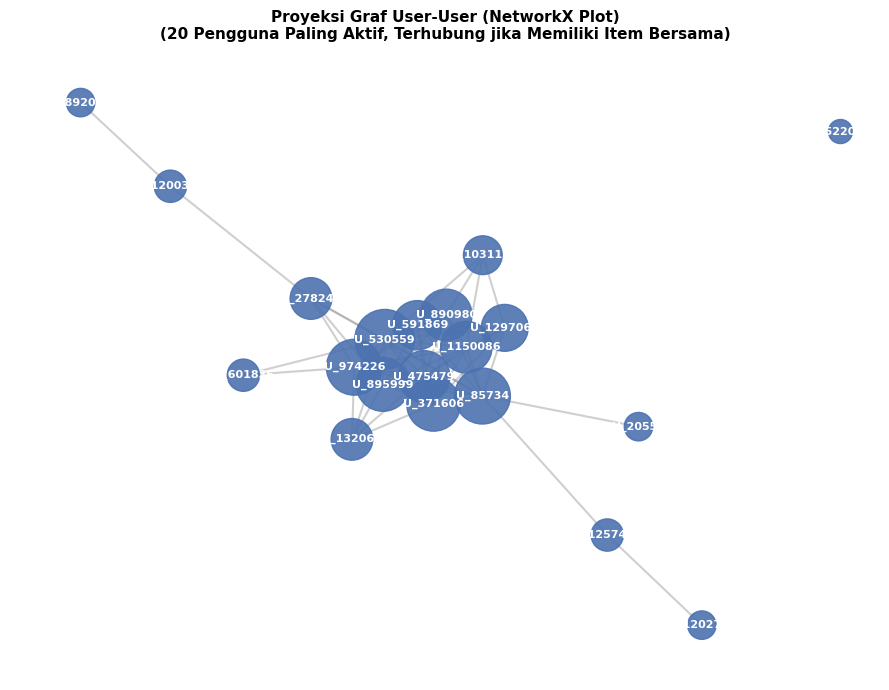

In [9]:
# Visualisasi Proyeksi User-User pada Subgraph Aktif menggunakan NetworkX
# Dua user terhubung jika berinteraksi dengan item yang sama (co-occurrence)
top_active_users = np.argsort(user_degrees)[::-1][:20]
top_u_ids = [idx2user[idx] for idx in top_active_users]

# Subgraf bipartite user-item untuk 20 user paling aktif
sub_df = train_agg[train_agg['visitorid'].isin(top_u_ids)]
B_user = nx.Graph()

for _, r in sub_df.iterrows():
    u_node = f"U_{int(r['visitorid'])}"
    i_node = f"I_{int(r['itemid'])}"
    B_user.add_node(u_node, bipartite=0)
    B_user.add_node(i_node, bipartite=1)
    B_user.add_edge(u_node, i_node, weight=r['weight'])

# Proyeksi one-mode ke User
user_nodes = [f"U_{u}" for u in top_u_ids]
G_user_proj = nx.bipartite.projected_graph(B_user, user_nodes)

plt.figure(figsize=(9, 7))
pos = nx.spring_layout(G_user_proj, seed=42, k=0.5)
node_sizes = [G_user_proj.degree(n) * 120 + 300 for n in G_user_proj.nodes()]

nx.draw_networkx_nodes(G_user_proj, pos, node_size=node_sizes, node_color="#4C72B0", alpha=0.9)
nx.draw_networkx_edges(G_user_proj, pos, alpha=0.4, edge_color="#888888", width=1.5)
nx.draw_networkx_labels(G_user_proj, pos, font_size=8, font_color="white", font_weight="bold")

plt.title("Proyeksi Graf User-User (NetworkX Plot)\n(20 Pengguna Paling Aktif, Terhubung jika Memiliki Item Bersama)", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

### Soal 2.1.5: Vector Space Modelling (VSM) terhadap Simpul Item
Pada VSM simpul Item:
* Setiap baris mewakili **vektor profil Item** $\mathbf{i}_k$.
* Setiap kolom mewakili dimensi pengguna (**Visitor**) $m$.
* Matriks ini merupakan hasil transpos dari matriks User-Item: $\mathbf{M}_{	ext{Item-User}} = \mathbf{M}_{	ext{User-Item}}^T$.

In [10]:
# Membangun Item-User Matrix (Transpose dari User-Item Matrix)
IU_matrix = UI_matrix.T.tocsr()

num_items_iu, num_users_iu = IU_matrix.shape
item_degrees = np.diff(IU_matrix.indptr)

print("="*45)
print("KARAKTERISTIK VSM SIMPUL ITEM (ITEM-USER MATRIX)")
print("="*45)
print(f"Dimensi / Shape : {num_items_iu:,} baris (Items) x {num_users_iu:,} kolom (Users)")
print(f"Total Elemen    : {num_items_iu * num_users_iu:,}")
print(f"Non-Zero Elemen : {IU_matrix.nnz:,}")
print(f"Sparsity        : {(1.0 - (IU_matrix.nnz / (num_items_iu * num_users_iu))) * 100:.5f} %")
print(f"Min Popularitas : {np.min(item_degrees)} user")
print(f"Max Popularitas : {np.max(item_degrees)} user")
print(f"Mean Popularitas: {np.mean(item_degrees):.2f} user")
print(f"Median Populart : {np.median(item_degrees):.1f} user")
print("="*45)

KARAKTERISTIK VSM SIMPUL ITEM (ITEM-USER MATRIX)
Dimensi / Shape : 22,788 baris (Items) x 25,321 kolom (Users)
Total Elemen    : 577,014,948
Non-Zero Elemen : 34,501
Sparsity        : 99.99402 %
Min Popularitas : 1 user
Max Popularitas : 51 user
Mean Popularitas: 1.51 user
Median Populart : 1.0 user


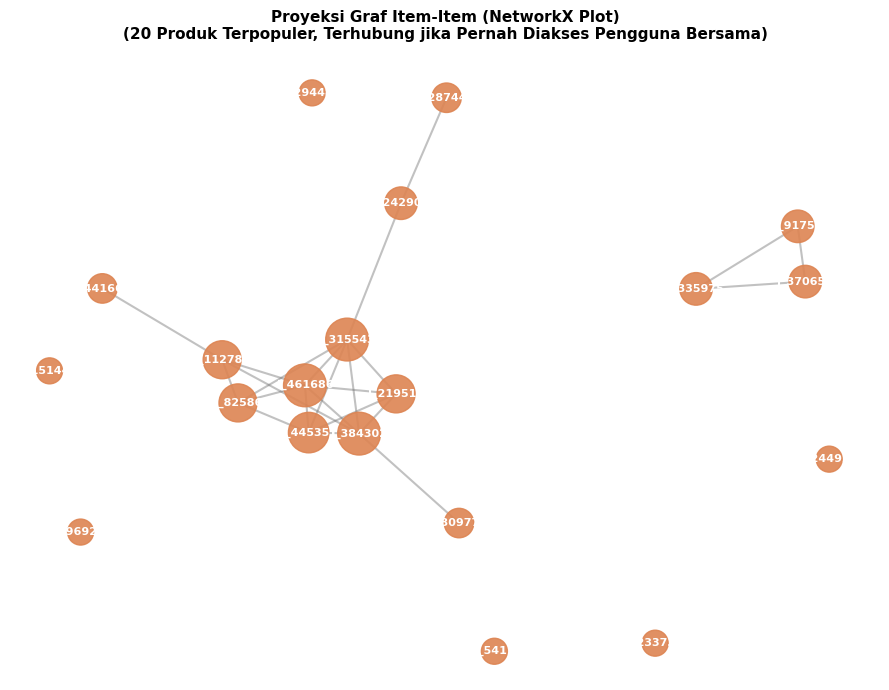

In [11]:
# Visualisasi Proyeksi Item-Item pada Subgraph Populer menggunakan NetworkX
# Dua item terhubung jika pernah diakses oleh pengguna yang sama
top_popular_items = np.argsort(item_degrees)[::-1][:20]
top_i_ids = [idx2item[idx] for idx in top_popular_items]

sub_item_df = train_agg[train_agg['itemid'].isin(top_i_ids)]
B_item = nx.Graph()

for _, r in sub_item_df.iterrows():
    u_node = f"U_{int(r['visitorid'])}"
    i_node = f"I_{int(r['itemid'])}"
    B_item.add_node(u_node, bipartite=0)
    B_item.add_node(i_node, bipartite=1)
    B_item.add_edge(u_node, i_node, weight=r['weight'])

# Proyeksi one-mode ke Item
item_nodes = [f"I_{it}" for it in top_i_ids]
G_item_proj = nx.bipartite.projected_graph(B_item, item_nodes)

plt.figure(figsize=(9, 7))
pos_item = nx.spring_layout(G_item_proj, seed=100, k=0.6)
node_sizes_item = [G_item_proj.degree(n) * 100 + 350 for n in G_item_proj.nodes()]

nx.draw_networkx_nodes(G_item_proj, pos_item, node_size=node_sizes_item, node_color="#DD8452", alpha=0.9)
nx.draw_networkx_edges(G_item_proj, pos_item, alpha=0.4, edge_color="#666666", width=1.5)
nx.draw_networkx_labels(G_item_proj, pos_item, font_size=8, font_color="white", font_weight="bold")

plt.title("Proyeksi Graf Item-Item (NetworkX Plot)\n(20 Produk Terpopuler, Terhubung jika Pernah Diakses Pengguna Bersama)", fontsize=11, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

### Soal 2.1.6: Analisis Komparasi: Proyeksi Manakah yang Lebih Baik (Efektif/Efisien)?

Berdasarkan eksplorasi empiris pada No. 4 dan No. 5, **Proyeksi Item-Item (Item-based)** jauh lebih **efektif dan efisien** dibandingkan Proyeksi User-User (User-based) untuk sistem rekomendasi graf *e-commerce*.

Berikut adalah uraian komparasi terperinci dari berbagai dimensi:

| Parameter Komparasi | Proyeksi User-User | Proyeksi Item-Item | Keunggulan |
| :--- | :--- | :--- | :--- |
| **Jumlah Simpul ($|V|$)** | $25.321$ nodes | $22.788$ nodes | **Item-Item** memiliki jumlah simpul lebih sedikit |
| **Stabilitas Temporal Profil** | Sangat dinamis (selera user berubah cepat, *session-dependent*) | Statis dan stabil (karakteristik produk tidak berubah) | **Item-Item** jauh lebih stabil dan tidak perlu sering dihitung ulang |
| **Kompleksitas Perhitungan Similarity** | Kompleksitas kuadratik $O(\|U\|^2)$ sangat berat saat jumlah user bertambah cepat | Relasi kemiripan antar item dapat dihitung secara *precomputed / offline* | **Item-Item** sangat efisien untuk skala produksi |
| **Karakteristik Komunitas Produk** | User sering menjelajah acak (*noisy browsing behavior*) | Produk memiliki relasi fungsional (substitusi/komplementer kuat) | **Item-Item** memiliki *cluster* graf yang lebih padat dan bermakna |
| ***Explainability* Rekomendasi** | Sulit dijelaskan ("Pengguna mirip Anda menyukai produk X") | Mudah dijelaskan ("Karena Anda melihat produk A, Anda mungkin suka produk B") | **Item-Item** memberikan transparansi rekomendasi yang lebih tinggi |

**Kesimpulan:**  
Proyeksi **Item-Item** dipilih sebagai fondasi analisis tahap selanjutnya (No. 7 dan No. 8) karena memberikan efisiensi komputasi yang tinggi dan keakuratan rekomendasi produk yang lebih relevan.

### Soal 2.1.7: Perhitungan Similarity pada Graf Terproyeksi (Python) & Penulisan Kembali ke Neo4j
Berdasarkan analisis No. 6, kita menggunakan **Cosine Similarity** antar-vektor item pada graf terproyeksi Item-Item.

Kita tentukan **Record Acuan**: Produk **Item `119736`** (salah satu item paling populer dengan 578 *co-occurrences* pada data pelatihan).

#### (a) CYPHER SQL untuk 5 Records dengan Similarity Tertinggi:
Setelah skor kemiripan ditulis ke dalam graf sebagai relasi `[:SIMILAR {score: ...}]`, kueri Cypher untuk mengambil 5 item termirip adalah:
```cypher
MATCH (ref:Item {itemId: 119736})-[s:SIMILAR]->(target:Item)
RETURN ref.itemId AS item_acuan, target.itemId AS item_mirip, s.score AS similarity_score
ORDER BY s.score DESC
LIMIT 5
```